In [39]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.ticker import FormatStrFormatter
import rioxarray as rxr
from sklearn import cluster
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score
from scipy.stats import mode
from scipy.ndimage import generic_filter
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import gc

In [40]:
# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


Original data shape: (224, 1182, 1223)
Original data range: [-32768, 7333]


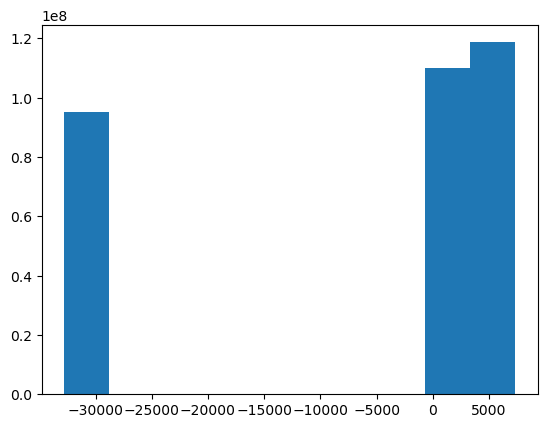

In [41]:
# Load the EnMAP data
data_enmap = rxr.open_rasterio('Datasets/ENMAP01-____L2A-DT0000160657_20251016T011429Z_002_V010502_20251017T031330Z-SPECTRAL_IMAGE.TIF').squeeze()
print(f"Original data shape: {data_enmap.shape}")
print(f"Original data range: [{data_enmap.min().values}, {data_enmap.max().values}]")
data_enmap.plot()
plt.title('')
plt.show()

Original data range: [0.0, 0.733299970626831]


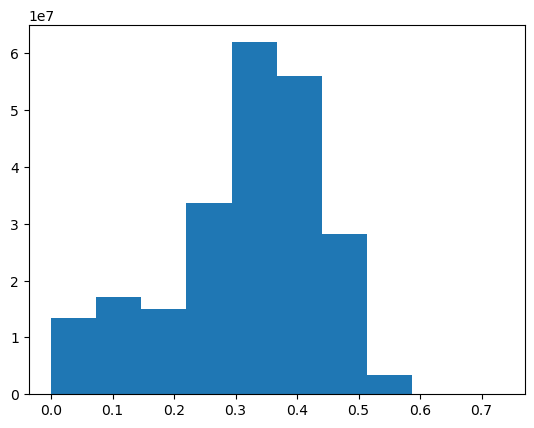

Spatial extent: [array(567090.), array(603750.), array(6712260.), array(6747690.)]


In [42]:
# Replace fill values with NaN
data_enmap = data_enmap.where(data_enmap >= 0)

# Scale to reflectance (0-1 range)
data_enmap = data_enmap / 10000.0
print(f"Original data range: [{data_enmap.min().values}, {data_enmap.max().values}]")
data_enmap.plot()
plt.title('')
plt.show()

# Get the spatial extent
extent = [data_enmap.x.min().values, data_enmap.x.max().values,
          data_enmap.y.min().values, data_enmap.y.max().values]
print(f"Spatial extent: {extent}")

In [43]:
# Prepare data with band-wise validation
# Get the shape
if len(data_enmap.shape) == 3:
    bands, rows, cols = data_enmap.shape
else:
    raise ValueError(f"Expected 3D data (bands, rows, cols), got shape {data_enmap.shape}")

print(f"Data shape: {bands} bands, {rows} rows, {cols} columns")
print(f"Total pixels: {rows * cols:,}")

# Reshape to 2D: (n_pixels, n_bands)
print("\nReshaping data...")
data_reshaped = data_enmap.values.reshape(bands, -1).T
print(f"Reshaped to: {data_reshaped.shape} (pixels × bands)")

Data shape: 224 bands, 1182 rows, 1223 columns
Total pixels: 1,445,586

Reshaping data...
Reshaped to: (1445586, 224) (pixels × bands)



STEP 1: IDENTIFYING VALID BANDS
Checking which bands have valid data...


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_1765/2315182216.py:10: RuntimeWarning: Mean of empty slice
  band_mean = np.nanmean(data_reshaped[:, band_idx])



Bands with valid data: 219 out of 224
Bands with NO valid data: 5
Problematic bands removed: [130, 131, 132, 133, 134]

STEP 2: KEEPING ONLY VALID BANDS
New data shape: (1445586, 219)
Removed 5 invalid bands

STEP 3: FILLING NaN VALUES WITH BAND MEANS
Filling NaN values with band means...
  Band 0 (original band 0): Filled 403469 NaNs with mean 0.0443
  Band 1 (original band 1): Filled 403702 NaNs with mean 0.0447
  Band 2 (original band 2): Filled 403041 NaNs with mean 0.0489
  Band 3 (original band 3): Filled 402919 NaNs with mean 0.0514
  Band 4 (original band 4): Filled 402710 NaNs with mean 0.0556
  Band 50 (original band 50): Filled 401494 NaNs with mean 0.2601
  Band 100 (original band 100): Filled 401487 NaNs with mean 0.3286
  Band 150 (original band 155): Filled 401489 NaNs with mean 0.4465
  Band 200 (original band 205): Filled 401483 NaNs with mean 0.3460

Total NaN values filled: 87,943,394

STEP 4: REMOVING COMPLETELY INVALID PIXELS

Final statistics:
  Original bands: 2

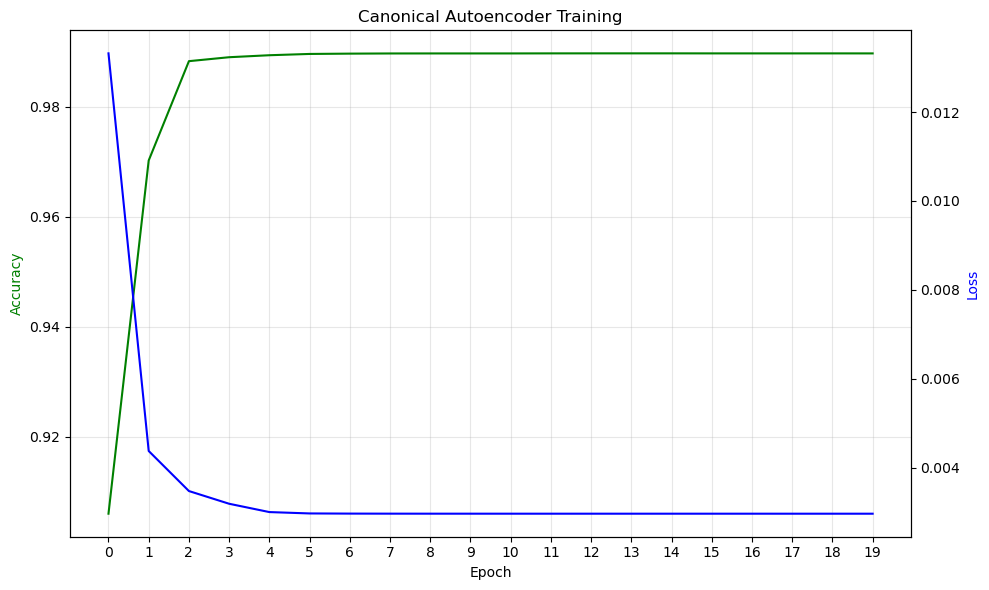


✓ Autoencoder training complete!
✓ Encoded representation ready: (1044103, 2)


In [44]:
# Step 1: Identify bands with valid data
print("\n" + "="*60)
print("STEP 1: IDENTIFYING VALID BANDS")
print("="*60)
print("Checking which bands have valid data...")
bands_with_data = []
bands_without_data = []

for band_idx in range(bands):
    band_mean = np.nanmean(data_reshaped[:, band_idx])
    if not np.isnan(band_mean):
        bands_with_data.append(band_idx)
    else:
        bands_without_data.append(band_idx)

print(f"\nBands with valid data: {len(bands_with_data)} out of {bands}")
print(f"Bands with NO valid data: {len(bands_without_data)}")

if len(bands_without_data) > 0:
    if len(bands_without_data) <= 20:
        print(f"Problematic bands removed: {bands_without_data}")
    else:
        print(f"First 20 problematic bands: {bands_without_data[:20]}")
        print(f"... and {len(bands_without_data) - 20} more")

# Step 2: Keep only valid bands
print("\n" + "="*60)
print("STEP 2: KEEPING ONLY VALID BANDS")
print("="*60)
data_reshaped_valid_bands = data_reshaped[:, bands_with_data]
print(f"New data shape: {data_reshaped_valid_bands.shape}")
print(f"Removed {len(bands_without_data)} invalid bands")

# Step 3: Fill remaining NaN values with band means
print("\n" + "="*60)
print("STEP 3: FILLING NaN VALUES WITH BAND MEANS")
print("="*60)
data_reshaped_filled = data_reshaped_valid_bands.copy()
print("Filling NaN values with band means...")
total_nans_filled = 0

for i, band_idx in enumerate(bands_with_data):
    band_data = data_reshaped_filled[:, i]
    nan_count = np.isnan(band_data).sum()
    
    if nan_count > 0:
        band_mean = np.nanmean(band_data)
        data_reshaped_filled[:, i] = np.where(np.isnan(band_data), band_mean, band_data)
        total_nans_filled += nan_count
        
        if i % 50 == 0 or i < 5:
            print(f"  Band {i} (original band {band_idx}): Filled {nan_count} NaNs with mean {band_mean:.4f}")

print(f"\nTotal NaN values filled: {total_nans_filled:,}")

# Step 4: Remove completely invalid pixels
print("\n" + "="*60)
print("STEP 4: REMOVING COMPLETELY INVALID PIXELS")
print("="*60)
nan_count_per_pixel = np.isnan(data_reshaped).sum(axis=1)
completely_invalid = nan_count_per_pixel == bands
data_valid = data_reshaped_filled[~completely_invalid]
valid_mask_full = ~completely_invalid

print(f"\nFinal statistics:")
print(f"  Original bands: {bands}")
print(f"  Valid bands used: {len(bands_with_data)}")
print(f"  Total pixels: {data_reshaped.shape[0]:,}")
print(f"  Completely invalid pixels removed: {completely_invalid.sum():,}")
print(f"  Valid pixels for autoencoder: {data_valid.shape[0]:,}")
print(f"  Final shape: {data_valid.shape}")
print(f"  NaN values remaining: {np.isnan(data_valid).sum()}")

if data_valid.shape[0] > 0 and np.isnan(data_valid).sum() == 0:
    print("\n✓ Data is ready for Autoencoder!")
else:
    raise ValueError("✗ Error: Data still has issues.")

# USE ALL DATA - NO SAMPLING
print("\n" + "="*60)
print("USING ALL DATA FOR AUTOENCODER TRAINING")
print("="*60)
data_train = data_valid.copy()
print(f"Training on ALL {data_train.shape[0]:,} pixels")
print(f"Training data shape: {data_train.shape}")
print(f"Training data size: {data_train.nbytes / 1024**2:.2f} MB")

print("="*60)
print("CHECKING YOUR ACTUAL DATA")
print("="*60)

# Check data type
print(f"data_train dtype: {data_train.dtype}")
print(f"data_train shape: {data_train.shape}")

# Check for problematic values
print(f"\nData statistics:")
print(f"  Min: {np.min(data_train)}")
print(f"  Max: {np.max(data_train)}")
print(f"  Mean: {np.mean(data_train)}")
print(f"  NaN count: {np.isnan(data_train).sum()}")
print(f"  Inf count: {np.isinf(data_train).sum()}")
print(f"  Negative values: {(data_train < 0).sum()}")
print(f"  Values > 1: {(data_train > 1).sum()}")

# Check if data is contiguous in memory
print(f"\nMemory layout:")
print(f"  Is C-contiguous: {data_train.flags['C_CONTIGUOUS']}")
print(f"  Is Fortran-contiguous: {data_train.flags['F_CONTIGUOUS']}")

# Convert to float32
print("\nConverting to float32...")
data_train_fixed = data_train.astype(np.float32)
print(f"New dtype: {data_train_fixed.dtype}")

# Make sure data is contiguous
if not data_train_fixed.flags['C_CONTIGUOUS']:
    print("Making data contiguous...")
    data_train_fixed = np.ascontiguousarray(data_train_fixed)
    print("✓ Data is now contiguous")

print("\n" + "="*60)
print("Data checks complete!")
print("="*60)

# Define the Autoencoder model
class Autoencoder(nn.Module):
    def __init__(self, input_dim, l1_lambda=1e-4):
        super(Autoencoder, self).__init__()
        self.l1_lambda = l1_lambda
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 6),
            nn.SELU(),
            nn.Linear(6, 4),
            nn.SELU(),
            nn.Linear(4, 2),
            nn.SELU()
        )
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(2, 4),
            nn.SELU(),
            nn.Linear(4, 6),
            nn.SELU(),
            nn.Linear(6, input_dim),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded
    
    def encode(self, x):
        return self.encoder(x)
    
    def l1_regularization(self):
        l1_loss = 0
        for param in self.parameters():
            l1_loss += torch.sum(torch.abs(param))
        return self.l1_lambda * l1_loss

# Hyperparameters
learning_rate = 1e-4
epochs = 20
batch_size = 64
encoding_dim = 2
input_dim = data_train_fixed.shape[1]

print(f"\nAutoencoder Configuration:")
print(f"  Input dimension: {input_dim} bands")
print(f"  Encoding dimension: {encoding_dim}")
print(f"  Training samples: {data_train_fixed.shape[0]:,}")
print(f"  Epochs: {epochs}")
print(f"  Batch size: {batch_size}")

# Convert to PyTorch tensors
print("\nConverting to PyTorch tensors...")
data_tensor = torch.FloatTensor(data_train_fixed).to(device)
print(f"Tensor shape: {data_tensor.shape}")
print(f"Tensor device: {data_tensor.device}")

# Create DataLoader
dataset = TensorDataset(data_tensor, data_tensor)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
print(f"Number of batches: {len(dataloader)}")

# Initialize model, loss function, and optimizer
model = Autoencoder(input_dim, l1_lambda=learning_rate).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

print("\n" + "="*60)
print("TRAINING AUTOENCODER")
print("="*60)

# Training
history = {'loss': [], 'accuracy': []}

for epoch in range(epochs):
    model.train()
    epoch_loss = 0
    epoch_correct = 0
    epoch_total = 0
    
    for batch_idx, (batch_x, batch_y) in enumerate(dataloader):
        # Forward pass
        outputs = model(batch_x)
        
        # Calculate loss (MSE + L1 regularization)
        mse_loss = criterion(outputs, batch_y)
        l1_loss = model.l1_regularization()
        loss = mse_loss + l1_loss
        
        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        # Track metrics
        epoch_loss += loss.item()
        
        # Calculate "accuracy" (percentage of predictions within threshold)
        with torch.no_grad():
            diff = torch.abs(outputs - batch_y)
            correct = (diff < 0.1).float().mean()
            epoch_correct += correct.item()
            epoch_total += 1
    
    avg_loss = epoch_loss / len(dataloader)
    avg_accuracy = epoch_correct / epoch_total
    
    history['loss'].append(avg_loss)
    history['accuracy'].append(avg_accuracy)
    
    print(f"Epoch [{epoch+1}/{epochs}], Loss: {avg_loss:.6f}, Accuracy: {avg_accuracy:.4f}")

print("\n" + "="*60)
print("ENCODING ALL DATA")
print("="*60)

# Encode all data
model.eval()
with torch.no_grad():
    data_ae = model.encode(data_tensor).cpu().numpy()

print(f"Encoded data shape: {data_ae.shape}")
print(f"Encoded data range: [{data_ae.min():.3f}, {data_ae.max():.3f}]")

# Plot training history
fig, ax1 = plt.subplots(figsize=(10, 6))
ax2 = ax1.twinx()
ax1.plot(history['accuracy'], 'g-', label='Accuracy')
ax2.plot(history['loss'], 'b-', label='Loss')
ax1.set_title('Canonical Autoencoder Training')
ax1.set_ylabel('Accuracy', color='g')
ax2.set_ylabel('Loss', color='b')
ax1.set_xlabel('Epoch')
ax1.set_xticks(list(range(epochs)))
ax1.grid(True, alpha=0.3)
ax2.grid(False)
plt.tight_layout()
plt.show()

# Free up memory
del data_tensor
if device.type == 'cuda':
    torch.cuda.empty_cache()
gc.collect()

print("\n✓ Autoencoder training complete!")
print(f"✓ Encoded representation ready: {data_ae.shape}")


ELBOW METHOD - FINDING OPTIMAL K
Testing different numbers of clusters...
  k=2: inertia=460155.06
  k=3: inertia=220026.61
  k=4: inertia=129304.47
  k=5: inertia=88214.58
  k=6: inertia=65327.33
  k=7: inertia=49576.92
  k=8: inertia=38560.07
  k=9: inertia=31157.95
  k=10: inertia=25690.12
  k=11: inertia=21832.72
  k=12: inertia=18504.95
  k=13: inertia=15881.52
  k=14: inertia=13929.95
  k=15: inertia=12504.52
  k=16: inertia=11236.21
  k=17: inertia=10305.30
  k=18: inertia=9168.28
  k=19: inertia=8157.07
  k=20: inertia=7604.60


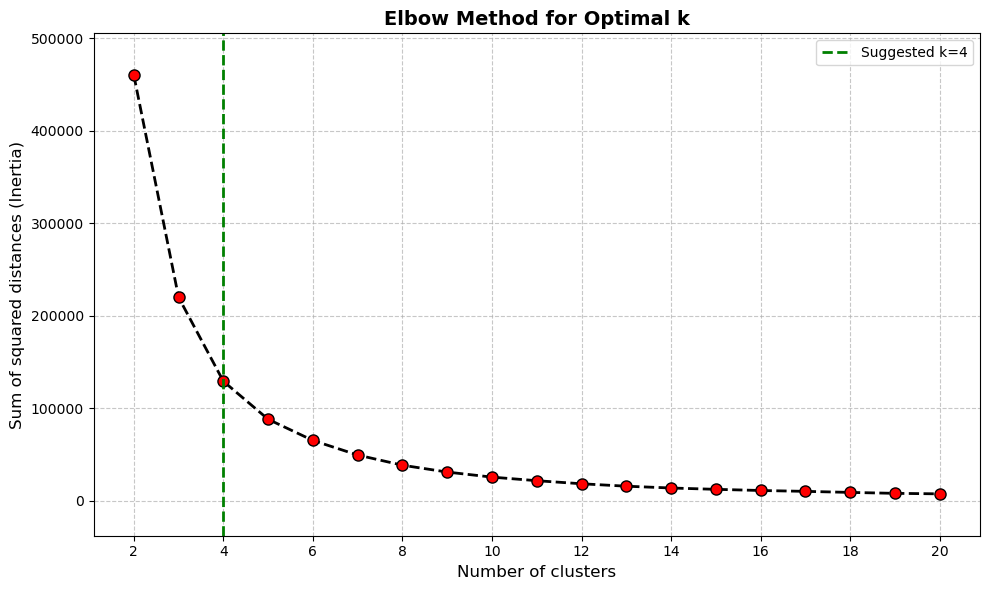


Elbow plot saved to 'ae_kmeans_enmap_elbow.png'


In [45]:
# Elbow method to find optimal number of clusters
print("\n" + "="*60)
print("ELBOW METHOD - FINDING OPTIMAL K")
print("="*60)

sum_squared_distance = []
range_n_clusters = range(2, 21)

print("Testing different numbers of clusters...")
for k in range_n_clusters:
    clusterer = cluster.KMeans(n_clusters=k, random_state=1)
    clusterer.fit(data_ae)
    sum_squared_distance.append(clusterer.inertia_)
    print(f"  k={k}: inertia={clusterer.inertia_:.2f}")

range_ssd = max(sum_squared_distance) - min(sum_squared_distance)

# Plot elbow graph
plt.figure(figsize=(10, 6))
plt.plot(range_n_clusters, sum_squared_distance, 'ko--', mfc='r', linewidth=2, markersize=8)
plt.vlines(x=4, ymin=min(sum_squared_distance)-(0.1*range_ssd),
           ymax=max(sum_squared_distance)+(0.1*range_ssd), color='g', linestyles='dashed', linewidth=2, label='Suggested k=4')
plt.xticks(range(2, 21, 2))
plt.ylim(min(sum_squared_distance)-(0.1*range_ssd), max(sum_squared_distance)+(0.1*range_ssd))
plt.xlabel('Number of clusters', fontsize=12)
plt.ylabel('Sum of squared distances (Inertia)', fontsize=12)
plt.title('Elbow Method for Optimal k', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig('ae_kmeans_enmap_elbow.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nElbow plot saved to 'ae_kmeans_enmap_elbow.png'")


K-MEANS CLUSTERING
Clustering with k=4...
✓ Clustering complete!
  Cluster labels shape: (1044103,)
  Unique clusters: [0 1 2 3]

Clustering Quality Metrics:
  Calinski-Harabasz score: 3267105.4089 (higher is better)
  Davies-Bouldin score: 0.5192 (lower is better)

Pixels per cluster:
  Cluster 0: 112,155 pixels (10.7%)
  Cluster 1: 334,028 pixels (32.0%)
  Cluster 2: 294,391 pixels (28.2%)
  Cluster 3: 303,529 pixels (29.1%)

RESHAPING LABELS TO SPATIAL DIMENSIONS
Spatial labels shape: (1182, 1223)
  Valid pixels: 1,044,103
  Invalid pixels: 401,483

Applying majority filter (7x7 window)...
✓ Filtering complete!

PLOTTING CLASSIFICATION MAP


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_1765/1147958843.py:74: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  im = ax.imshow(data, extent=extent, cmap=plt.cm.get_cmap('tab10', n_clusters),


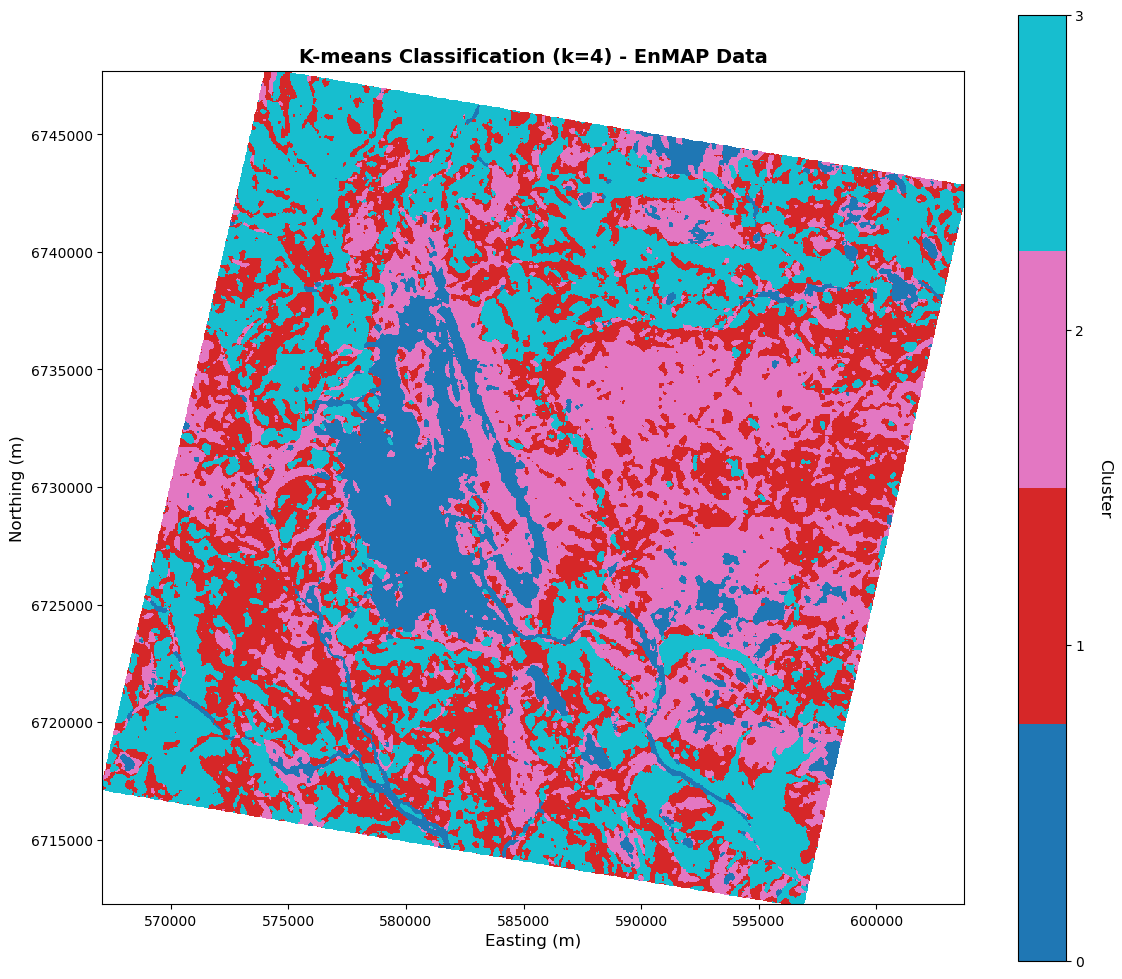


✓ Classification map saved to 'ae_kmeans_enmap_classification.png'

Creating comparison plot...


/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_1765/1147958843.py:111: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('tab10', n_clusters),
/var/folders/lb/xql52k216cs7q6f5_qxr0f3r0000gn/T/ipykernel_1765/1147958843.py:121: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap=plt.cm.get_cmap('tab10', n_clusters),


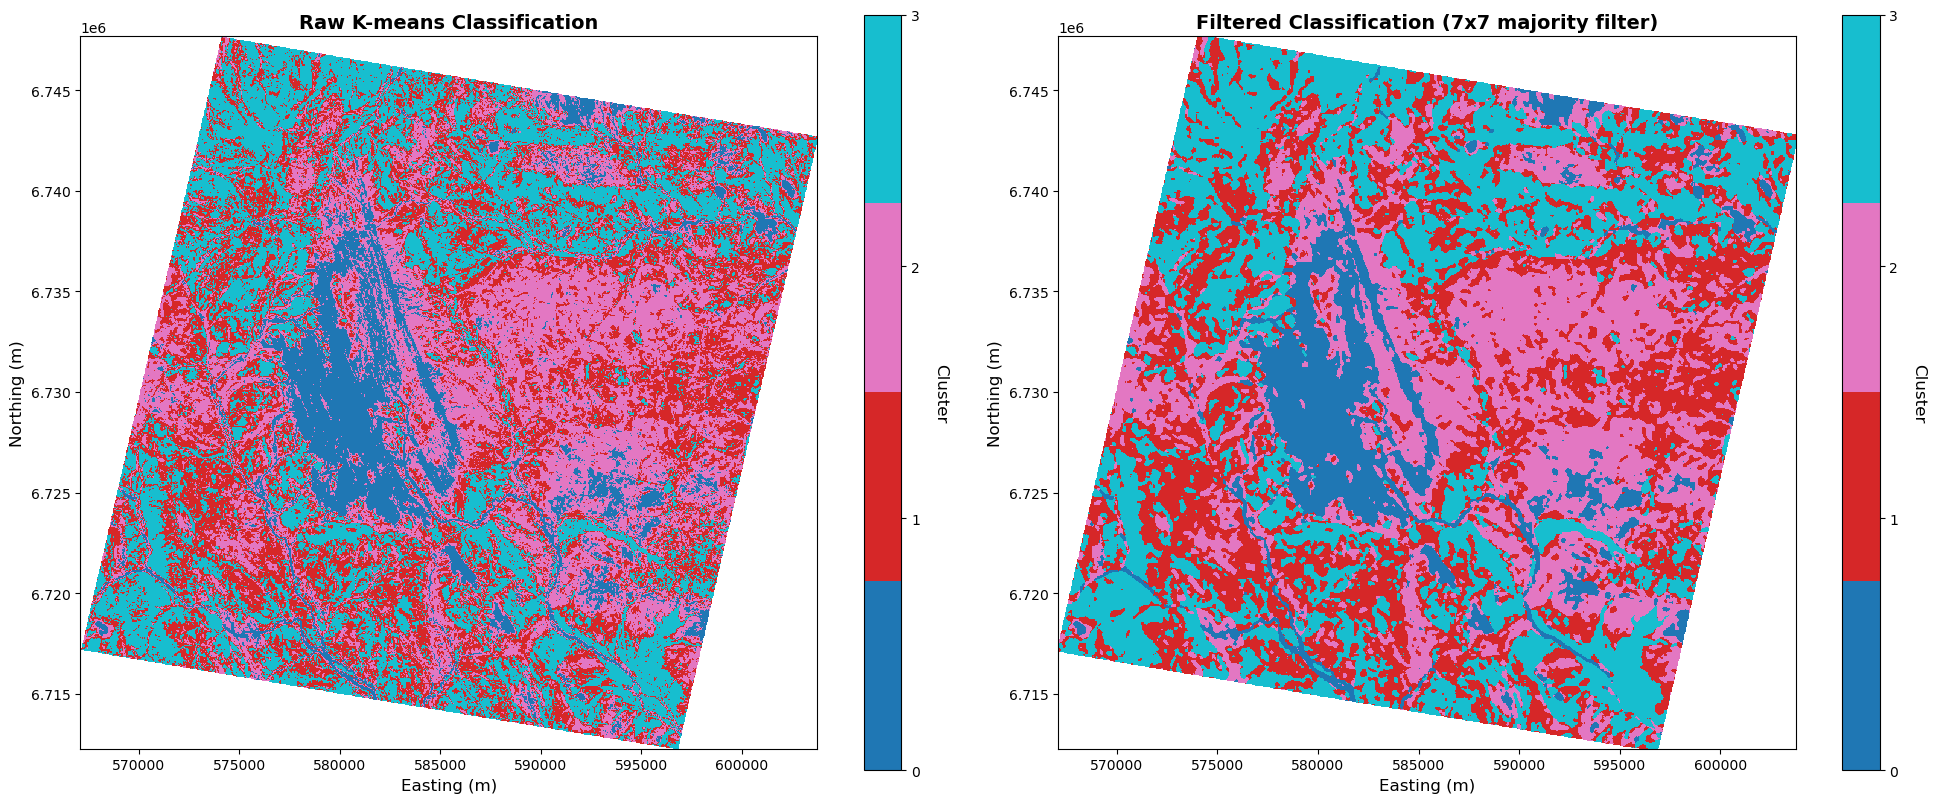

✓ Comparison plot saved to 'ae_kmeans_enmap_comparison.png'


In [46]:
# K-means clustering with chosen k
print("\n" + "="*60)
print("K-MEANS CLUSTERING")
print("="*60)

n_clusters = 4
print(f"Clustering with k={n_clusters}...")

# Create and train the classifier
clusterer = cluster.KMeans(n_clusters=n_clusters, random_state=1)
pred = clusterer.fit_predict(data_ae)

# Get cluster labels
labels = clusterer.labels_

print(f"✓ Clustering complete!")
print(f"  Cluster labels shape: {labels.shape}")
print(f"  Unique clusters: {np.unique(labels)}")

# Calculate clustering metrics
ch_score = calinski_harabasz_score(data_ae, labels)
db_score = davies_bouldin_score(data_ae, labels)

print(f"\nClustering Quality Metrics:")
print(f"  Calinski-Harabasz score: {round(ch_score, 4)} (higher is better)")
print(f"  Davies-Bouldin score: {round(db_score, 4)} (lower is better)")

# Count pixels per cluster - FIXED LINE
unique = np.unique(labels)
counts = np.bincount(labels)
print(f"\nPixels per cluster:")
for cluster_id, count in enumerate(counts):
    print(f"  Cluster {cluster_id}: {count:,} pixels ({100*count/len(labels):.1f}%)")

# Reshape labels back to spatial dimensions
print("\n" + "="*60)
print("RESHAPING LABELS TO SPATIAL DIMENSIONS")
print("="*60)

# Create a full array with NaN for invalid pixels
labels_full = np.full(valid_mask_full.shape, np.nan)
# Fill in the valid pixels with cluster labels
labels_full[valid_mask_full] = labels

# Reshape to original spatial dimensions
labels_spatial = labels_full.reshape(rows, cols)
print(f"Spatial labels shape: {labels_spatial.shape}")
print(f"  Valid pixels: {(~np.isnan(labels_spatial)).sum():,}")
print(f"  Invalid pixels: {np.isnan(labels_spatial).sum():,}")

# Define the filter function for majority filtering
def filter_function(values):
    """Return the most common value in the neighborhood, ignoring NaN"""
    valid_values = values[~np.isnan(values)]
    if len(valid_values) == 0:
        return np.nan
    mode_result = mode(valid_values, keepdims=True)
    return mode_result.mode[0]

# Apply majority filter to smooth the results
print("\nApplying majority filter (7x7 window)...")
labels_major = generic_filter(labels_spatial, function=filter_function, size=7)
print(f"✓ Filtering complete!")

# Define plot_map function
def plot_map(data, extent, n_clusters, title='K-means Classification'):
    """Plot the classification map"""
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Create custom colormap
    colors = plt.cm.tab10(np.linspace(0, 1, n_clusters))
    
    # Plot the data
    im = ax.imshow(data, extent=extent, cmap=plt.cm.get_cmap('tab10', n_clusters), 
                   interpolation='nearest', vmin=0, vmax=n_clusters-1)
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax, ticks=range(n_clusters))
    cbar.set_label('Cluster', rotation=270, labelpad=20, fontsize=12)
    
    # Labels and formatting
    ax.set_xlabel('Easting (m)', fontsize=12)
    ax.set_ylabel('Northing (m)', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    
    # Format axis ticks
    ax.xaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    ax.yaxis.set_major_formatter(FormatStrFormatter('%.0f'))
    
    plt.tight_layout()
    return fig, ax

# Plot the classification map
print("\n" + "="*60)
print("PLOTTING CLASSIFICATION MAP")
print("="*60)

fig, ax = plot_map(labels_major, extent, n_clusters, 
                   title=f'K-means Classification (k={n_clusters}) - EnMAP Data')
plt.savefig('ae_kmeans_enmap_classification.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Classification map saved to 'ae_kmeans_enmap_classification.png'")

# Plot both raw and filtered classifications side by side
print("\nCreating comparison plot...")
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Raw classification
im1 = axes[0].imshow(labels_spatial, extent=extent, 
                     cmap=plt.cm.get_cmap('tab10', n_clusters), 
                     interpolation='nearest', vmin=0, vmax=n_clusters-1)
axes[0].set_title('Raw K-means Classification', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Easting (m)', fontsize=12)
axes[0].set_ylabel('Northing (m)', fontsize=12)
cbar1 = plt.colorbar(im1, ax=axes[0], ticks=range(n_clusters))
cbar1.set_label('Cluster', rotation=270, labelpad=20, fontsize=12)

# Filtered classification
im2 = axes[1].imshow(labels_major, extent=extent, 
                     cmap=plt.cm.get_cmap('tab10', n_clusters), 
                     interpolation='nearest', vmin=0, vmax=n_clusters-1)
axes[1].set_title('Filtered Classification (7x7 majority filter)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Easting (m)', fontsize=12)
axes[1].set_ylabel('Northing (m)', fontsize=12)
cbar2 = plt.colorbar(im2, ax=axes[1], ticks=range(n_clusters))
cbar2.set_label('Cluster', rotation=270, labelpad=20, fontsize=12)

plt.tight_layout()
plt.savefig('ae_kmeans_enmap_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Comparison plot saved to 'ae_kmeans_enmap_comparison.png'")

In [47]:
# SAVE FOR EVALUATION
np.save('ca_encoded_data.npy', data_ae)
np.save('ca_labels_spatial.npy', labels_major)
print(f"✓ Saved CA results")

✓ Saved CA results
